In [3]:
import warnings
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from sklearn.datasets import fetch_openml
from sklearn.ensemble import AdaBoostClassifier
from sklearn.linear_model import Perceptron
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils import resample
from tqdm.auto import tqdm
from xgboost import DMatrix, XGBClassifier


## 1. Utilisation AdaBoost
import des données MNIST

In [4]:
X_mnist, y_mnist = fetch_openml('mnist_784', return_X_y=True, as_frame=False)
y_mnist = y_mnist.astype(np.int8)  # Convert labels to integers
X_mnist = X_mnist / 255.0

X_train, X_test, y_train, y_test = train_test_split(X_mnist, y_mnist, test_size=0.2, random_state=42, stratify= y_mnist)

découpage des données pour plusieurs taches de reconnaissance :
- 3 vs 8
- 0-4 vs 5-9
- 0 vs 1 vs 2 vs ... vs 9

In [5]:
def make_versus(classes_a, classes_b, N_train=None, N_test=None):
    '''
    créer les sous-listes contennant les individus des groupes de classes a et b
    label 0 : classes_a
    label 1 : classes_b
    '''
    def sel(Xs, ys, n):
        if n == None:
            n=-1
        m = np.isin(ys, classes_a + classes_b)
        Xs, ys = Xs[m][:n], ys[m][:n]
        return Xs, np.isin(ys, classes_b).astype(int)
    X_tr, y_tr = sel(X_train, y_train, N_train)
    X_te, y_te = sel(X_test, y_test, N_test)
    return X_tr, X_te, y_tr, y_te

VERSUS = {
    "3 vs 8": make_versus([3], [8]),
    "0-4 vs 5-9": make_versus([0,1,2,3,4], [5,6,7,8,9]),
    "versus all number": [X_train, X_test, y_train, y_test]
}

for title, (X_tr, X_te, y_tr, y_te) in VERSUS.items():
    print(title, "| train :", X_tr.shape, "| test :", X_te.shape)

3 vs 8 | train : (11172, 784) | test : (2792, 784)
0-4 vs 5-9 | train : (55999, 784) | test : (13999, 784)
versus all number | train : (56000, 784) | test : (14000, 784)


Choisir plusieurs paramètre de AdaBoost : 
- Learning rate
- Choisir le classifieur faibles : 
  - arbres avec profondeur variable
  - perceptron
- nombre d'estimateurs/de classifieur d'affilé (étapes de boosting)    

In [7]:
from pathlib import Path

etapes = [10, 50, 100]

LR = [1, 0.5, 0.1]

classif_faible = {
    "arbre d=8":  DecisionTreeClassifier(max_depth=8),
    "arbre d=5":  DecisionTreeClassifier(max_depth=5),
    "arbre d=3":  DecisionTreeClassifier(max_depth=3),
    "arbre d=1 (stump)":  DecisionTreeClassifier(max_depth=1),
    "perceptron": Perceptron(max_iter=20, tol=1e-4, random_state=0)
}

def make_ada(classif_faible, n, lr=0.1):
    return AdaBoostClassifier(estimator=classif_faible, n_estimators=n, learning_rate=lr, random_state=0)

def entrainer_unit(tache, nom, lr, X_tr, X_te, y_tr):
    '''
    entrainer un adaboost
    '''
    ab = make_ada(classif_faible[nom], max(etapes), lr).fit(X_tr, y_tr)
    save = list(ab.staged_predict(X_te))
    preds_s = {s: save[min(s, len(save)) - 1] for s in etapes}
    return (tache, nom, lr), ab, preds_s

def entrainer(tasks):
    '''
    entrainer nos adaboost pour chaque (tache, classifieur faible, lr)
    un seul fit avec max(etapes) estimators, puis staged_predict pour lire les prédictions à chaque étape
    preds[(tache, nom, lr, s)] = prédictions sur le test
    paralleliser les calculs avec delayed et entrainer_unit
    '''
    combis = product(tasks.items(), classif_faible, LR)
    total = len(tasks) * len(classif_faible) * len(LR)
    res = Parallel(n_jobs=-1, return_as="generator_unordered")(
        delayed(entrainer_unit)(tache, nom, lr, X_tr, X_te, y_tr)
        for (tache, (X_tr, X_te, y_tr, y_te)), nom, lr in combis
    )
    models, preds = {}, {}
    for clef, ab, preds_s in tqdm(res, total=total, desc="Entrainement"):
        models[clef] = ab
        for s, y_pred in preds_s.items():
            preds[clef + (s,)] = y_pred
    return models, preds

def sauvegarder(fig, nom):
    '''enregistre la figure dans save/nom.png (le dossier est créé s'il n'existe pas)'''
    Path("save").mkdir(exist_ok=True)
    fig.savefig(Path("save") / f"{nom.replace(' ', '_')}.png", dpi=100, bbox_inches="tight")

def afficher_mc(tasks, preds, lrs=[], titre="", prefixe=""):
    '''matrices de confusion : lignes = classif faible, colonnes = groupes par lr, puis étapes dans chaque groupe
    lrs : liste des lr à afficher (vide = tous les LR)
    prefixe : début du nom de fichier sauvegardé (pour ne pas écraser entre deux appels)'''
    lrs = lrs if len(lrs) > 0 else LR
    rows = []
    for tache, (X_tr, X_te, y_tr, y_te) in tasks.items():
        fig = plt.figure(figsize=(5*len(etapes)*len(lrs), 5*len(classif_faible)), constrained_layout=True)
        subfigs = fig.subfigures(1, len(lrs), squeeze=False)[0]
        for k, lr in enumerate(lrs):
            axes = subfigs[k].subplots(len(classif_faible), len(etapes), squeeze=False)
            subfigs[k].suptitle(f"lr = {lr}", fontsize=16)
            for i, nom in enumerate(classif_faible):
                for j, s in enumerate(etapes):
                    y_pred = preds[(tache, nom, lr, s)]
                    acc = accuracy_score(y_te, y_pred)
                    rows.append({"tache": tache, "classifieur faible": nom, "lr": lr, "étapes": s, "accuracy": acc})
                    ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred)).plot(ax=axes[i,j], colorbar=False, cmap="Blues")
                    axes[i,j].set_title(f"{nom}, {s} etapes \n acc = {acc:.3f}")
        fig.suptitle(f"Matrices de confusion - {tache} {titre}", fontsize=18)
        sauvegarder(fig, f"{prefixe}mc_{tache}_lr{'-'.join(map(str, lrs))}")
        plt.show()
    df = pd.DataFrame(rows)
    return df.pivot_table(index=["tache", "classifieur faible"], columns=["lr", "étapes"], values="accuracy").round(3)

def afficher_acc(tasks, preds, titre="", prefixe=""):
    '''
    une figure par tache : colonnes = n_estimators (etapes)
    chaque case = matrice d'accuracy (axe y : classifieur faible, axe x : learning rate)
    prefixe : début du nom de fichier sauvegardé (pour ne pas écraser entre deux appels)
    '''
    for tache, (X_tr, X_te, y_tr, y_te) in tasks.items():
        acc = {k: accuracy_score(y_te, v) for k, v in preds.items() if k[0] == tache}
        vmin, vmax = min(acc.values()), max(acc.values())
        fig, axes = plt.subplots(1, len(etapes), figsize=(5*len(etapes), 4), constrained_layout=True, squeeze=False)
        for j, s in enumerate(etapes):
            M = np.array([[acc[(tache, nom, lr, s)] for lr in LR] for nom in classif_faible])
            ax = axes[0,j]
            im = ax.imshow(M, cmap="viridis", vmin=vmin, vmax=vmax, aspect="auto")
            ax.set_xticks(range(len(LR)), LR)
            ax.set_yticks(range(len(classif_faible)), list(classif_faible))
            ax.set_xlabel("learning rate")
            ax.set_ylabel("classifieur faible")
            ax.set_title(f"n_estimators = {s}")
            for a in range(len(classif_faible)):
                for b in range(len(LR)):
                    ax.text(b, a, f"{M[a,b]:.3f}", ha="center", va="center", fontsize=8,
                            color="white" if M[a,b] < (vmin+vmax)/2 else "black")
        fig.colorbar(im, ax=axes, shrink=0.6, label="accuracy")
        fig.suptitle(f"Accuracy - {tache} {titre}")
        sauvegarder(fig, f"{prefixe}acc_{tache}")
        plt.show()

**Ne lancer d'une fois, cellelue qui met du temps a tourner**

In [5]:
models, preds = entrainer(VERSUS)

Entrainement:   0%|          | 0/45 [00:00<?, ?it/s]

In [ ]:
afficher_mc(VERSUS, preds, lrs=[]) #lrs=[] rend pour tout les LR
afficher_acc(VERSUS, preds)

NameError: name 'afficher_mc' is not defined

**Comentaire hyperparamètres :**  
augmenter profondeur arbre = augmenter les capacités de classification MAIS augmente beaucoup le temps de calcul  
Les arbres dans ce cas marchent bien avec des Learning rate plutot haut  
Le perceptron par contre fonctionne avec un LR plus bas (il faudrait retester avec LR = 0.01 ...), on pourrait aussi tester max_iter variable (mais trop long)  



## Carte de saillance

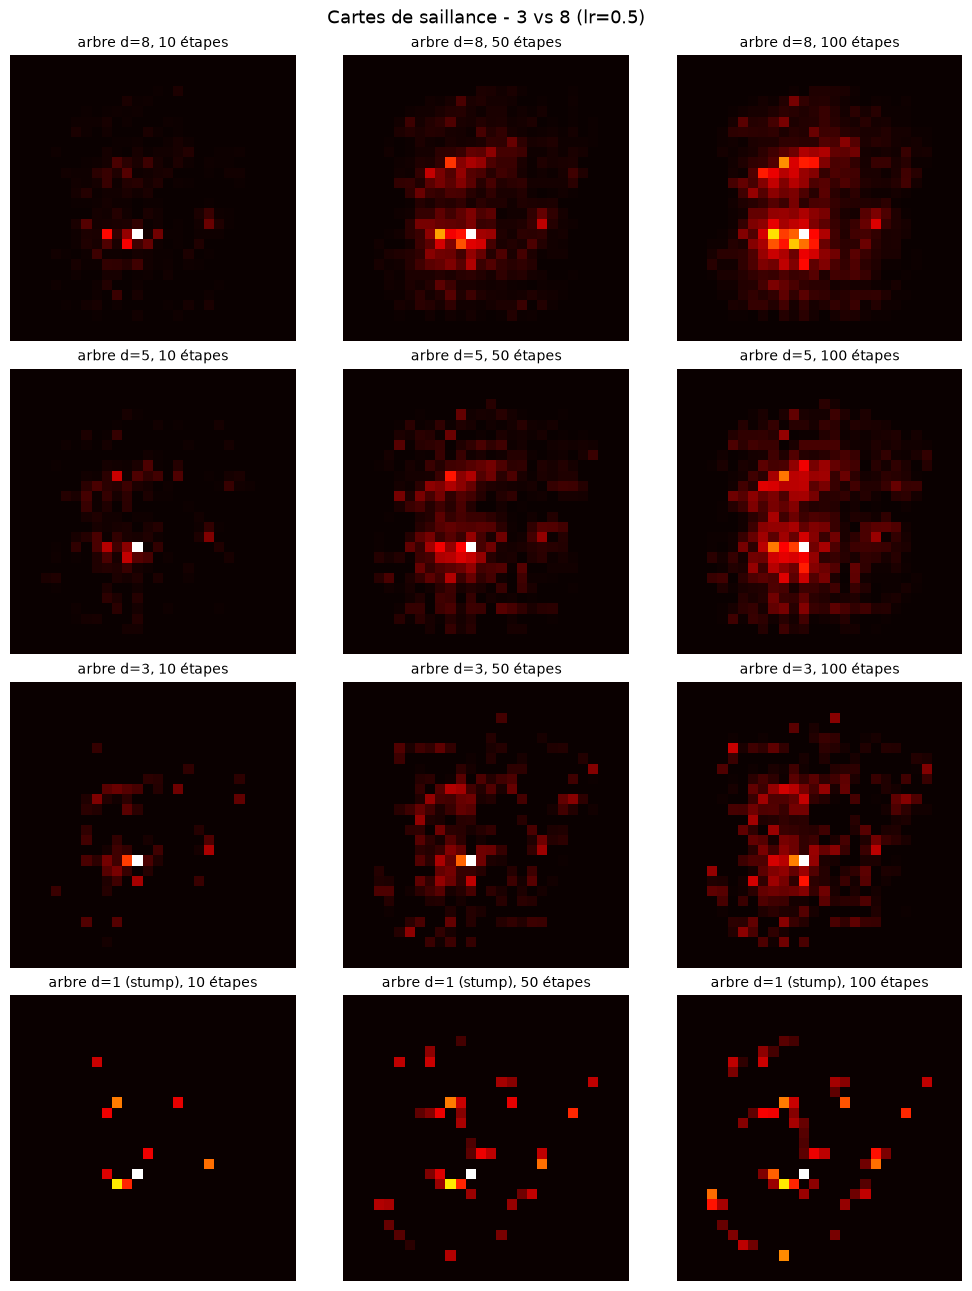

In [30]:
def saillance_pixels(ab, n):
    s = np.zeros(784)
    for arbre, alpha in zip(ab.estimators_[:n], ab.estimator_weights_[:n]):
        if hasattr(arbre, "feature_importances_"):
            s += alpha * arbre.feature_importances_
    return s.reshape(28, 28)

def tracer_cartes(models, tache, noms, fct_saillance, lr=LR[0], prefixe=""):
    fig, axes = plt.subplots(len(noms), len(etapes), figsize=(10, 3.2 * len(noms)), constrained_layout=True)
    for i, nom in enumerate(noms):
        for j, s in enumerate(etapes):
            axes[i, j].imshow(fct_saillance(models[(tache, nom, lr)], s), cmap="hot")
            axes[i, j].set_title(f"{nom}, {s} étapes", fontsize=10)
            axes[i, j].axis("off")
    fig.suptitle(f"Cartes de saillance - {tache} (lr={lr})", fontsize=13)
    sauvegarder(fig, f"{prefixe}saillance_{tache}_lr{lr}")
    plt.show()

tracer_cartes(models, list(VERSUS.keys())[0], list(classif_faible.keys())[:-1], saillance_pixels, lr=0.5, prefixe="pixels_")

Les pixels négatifs tendent vers un 8  
Le positif tend vers un 3

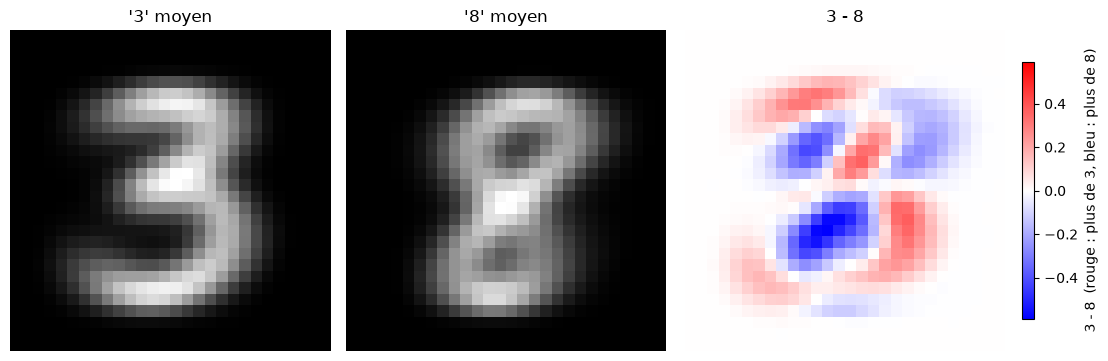

In [ ]:
# Pour comparer : image moyenne des 3 et des 8, et leur différence
Xa, Xb, ya, yb = VERSUS['3 vs 8']
m3, m8 = Xa[ya == 0].mean(axis=0).reshape(28, 28), Xa[ya == 1].mean(axis=0).reshape(28, 28)
diff = m3 - m8
vmax = np.abs(diff).max()

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), constrained_layout=True)
im0 = axes[0].imshow(m3, cmap="gray"); axes[0].set_title("'3' moyen")
im1 = axes[1].imshow(m8, cmap="gray"); axes[1].set_title("'8' moyen")
im2 = axes[2].imshow(diff, cmap="bwr", vmin=-vmax, vmax=vmax); axes[2].set_title("3 - 8")
for ax in axes:
    ax.axis("off")
fig.colorbar(im2, ax=axes[2], shrink=0.8, label="3 - 8  (rouge : plus de 3, bleu : plus de 8)")
sauvegarder(fig, "moyenne_3_8_et_difference")
plt.show()

## 3. Embedding
### 3.0 construction embedding
**embed(X) :**  
fonction transformant :   
- une image d'entrée X (784 pixels)    
- en un vecteur représentation (64 scalaires)   
utilisant les paramètres appris par la couche cachée du MLP (W et b)  

On a un apprentissage embeding : MLP avec 1 couche cachée de 64 neurones (avec activation ReLU).  
L'activation des 64 neurones cachés devient la nouvelle description/representation des images.  
L'auto-encodeur (couche cachée) est appris sans les labels (= non supervisé), sur des images d'entrainement uniquement (et appliqué sur les images d'entrainement et de validation/test)  



Erreur de reconstruction (MSE) : 0.009440012408036845


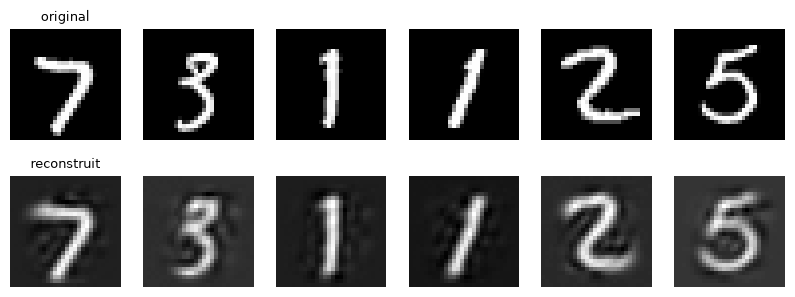

In [ ]:
N_HIDDEN = 64
ae = MLPRegressor(hidden_layer_sizes=(N_HIDDEN,), activation="relu", max_iter=50, random_state=0)
ae.fit(X_train, X_train)

W, b = ae.coefs_[0], ae.intercepts_[0]   # W : (784, 64)

def embed(X): # activation ReLU
    '''
    fonction transformant :
    - une image d'entrée X (784 pixels) 
    - en un vecteur représentation (64 scalaires)
    utilisant les paramètres appris par la couche cachée du MLP (W et b)
    '''
    return np.maximum(0, X @ W + b) 

print("Erreur de reconstruction (MSE) :", np.mean((ae.predict(X_test[:2000]) - X_test[:2000]) ** 2))

fig, axes = plt.subplots(2, 6, figsize=(10, 3.5))
for k in range(6):
    axes[0, k].imshow(X_test[k].reshape(28, 28), cmap="gray"); axes[0, k].axis("off")
    axes[1, k].imshow(ae.predict(X_test[k:k+1]).reshape(28, 28), cmap="gray"); axes[1, k].axis("off")
axes[0, 0].set_title("original", fontsize=9); axes[1, 0].set_title("reconstruit", fontsize=9)
sauvegarder(fig, "autoencodeur_originaux_vs_reconstruits")
plt.show()

### 3.1 AdaBoost dans l'espace d'embedding

**Ne lancer d'une fois, cellelue qui met du temps a tourner**

In [ ]:
VERSUS_E = {t: (embed(X_train), embed(X_test), y_train, y_test) for t, (X_train, X_test, y_train, y_test) in VERSUS.items()}
### On refait l'entrainement du boosting, mais avec les images d'entrée passé par la modif de representation (embedding)
models_E, preds_E = entrainer(VERSUS_E)

Entrainement:   0%|          | 0/45 [00:00<?, ?it/s]

VERSUS


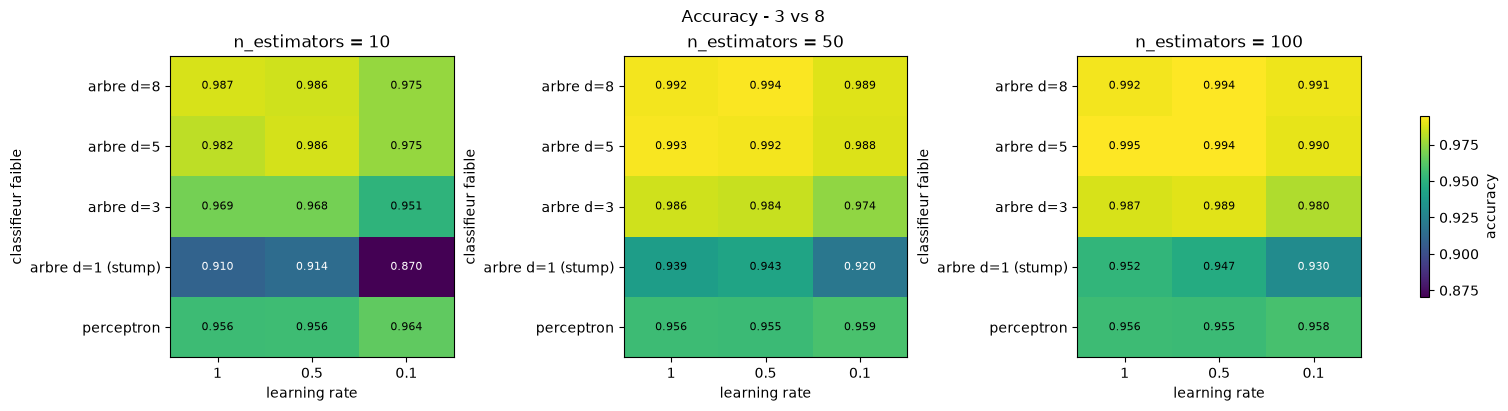

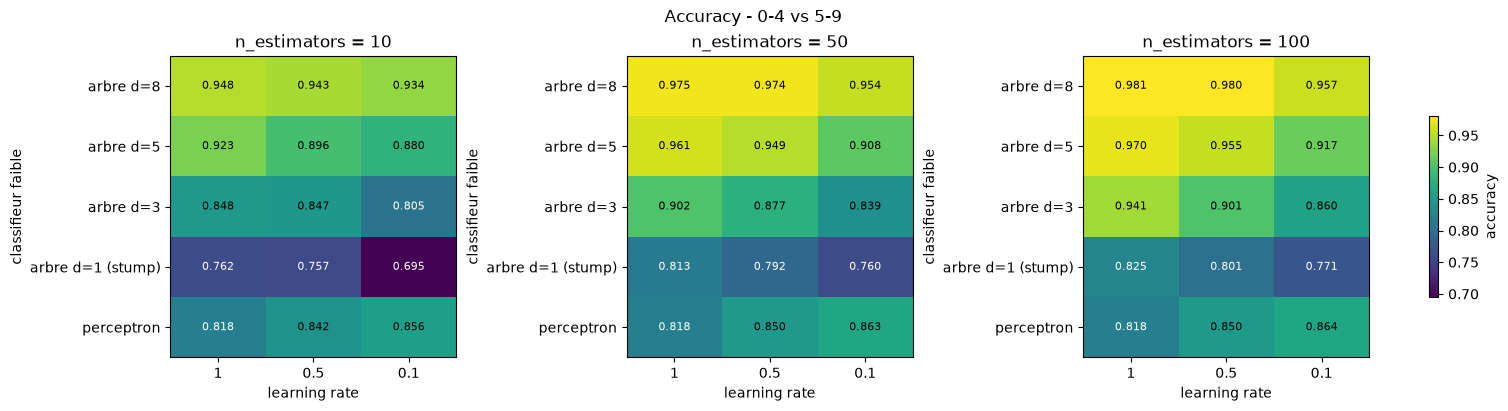

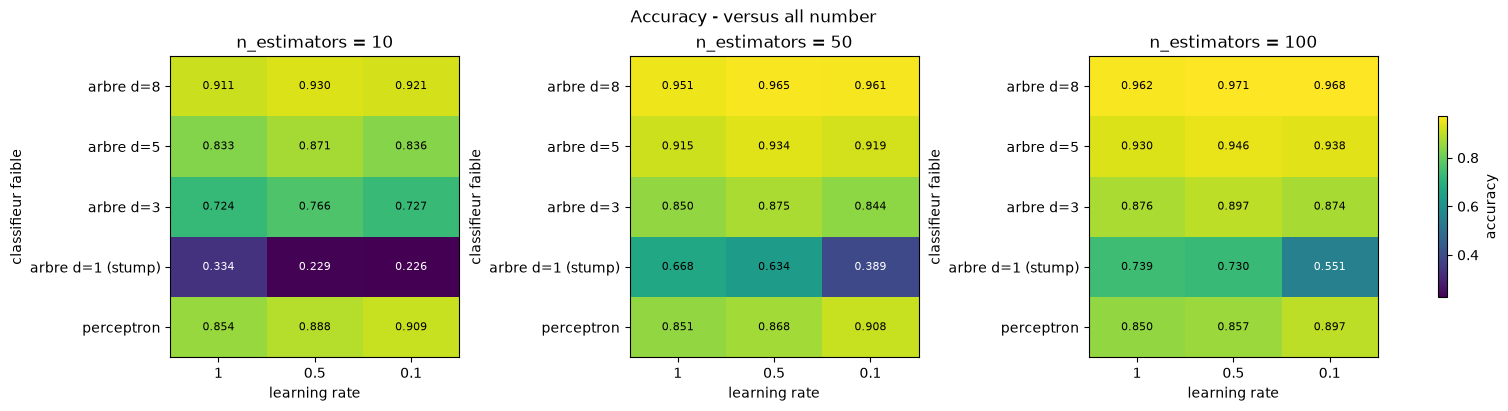

VERSUS_Embedding


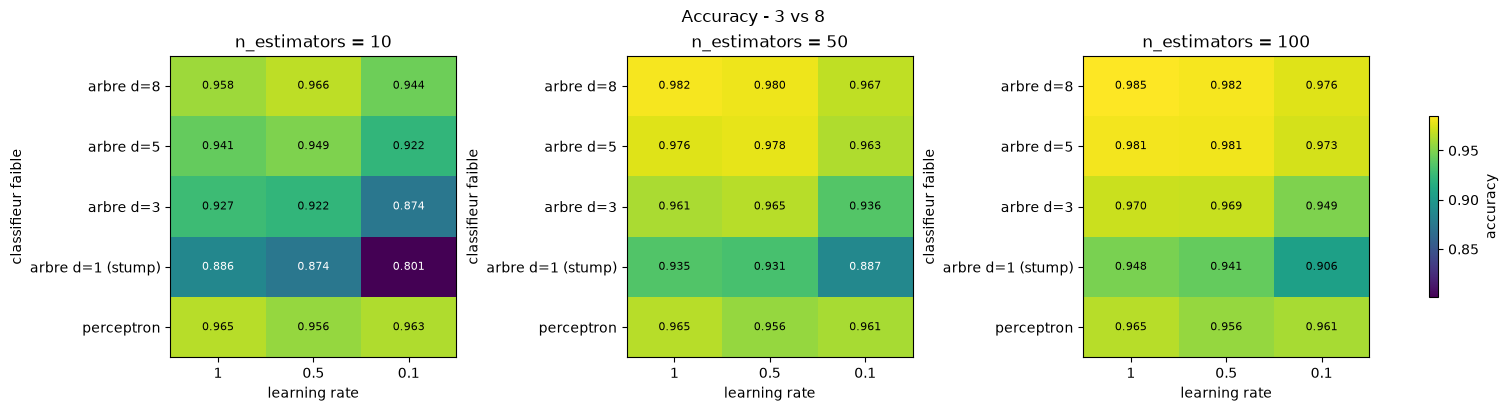

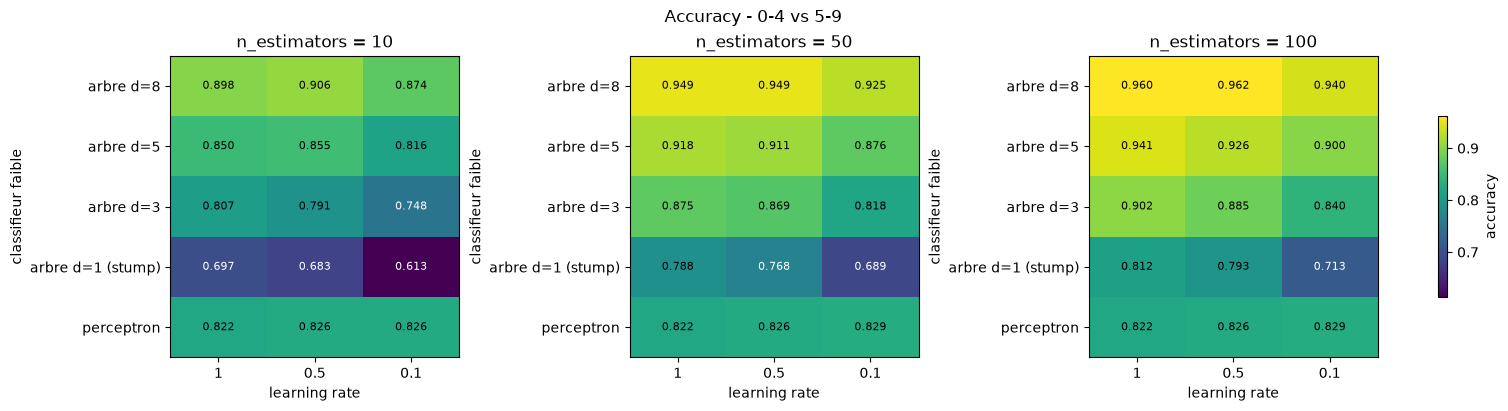

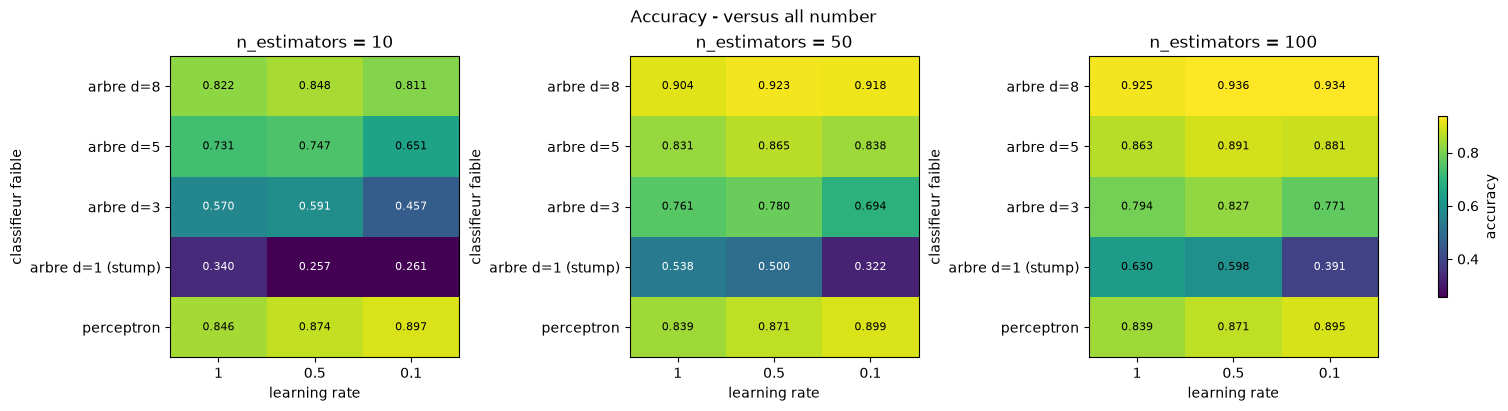

In [33]:
print("VERSUS")
afficher_acc(VERSUS, preds, prefixe="pixels_")
print("VERSUS_Embedding")
afficher_acc(VERSUS_E, preds_E, prefixe="embedding_")

### 3.2 Cartes de saillance dans l'espace des pixels
Les stumps testent maintenant un neurone caché.  
L'importance $imp_j$ d'un neurone est la somme des $\alpha_t$ des étapes qui le testent. On la rétropropage vers les pixels, comme dans GradCAM : pour une image $x$, la contribution du pixel $p$ est :
$$s_p(x) = \sum_j imp_j \cdot \mathbb{1}[z_j(x) > 0] \cdot W_{pj}$$
(la dérivée de $z_j = \text{ReLU}(x W + b)$ par rapport à $x_p$). La carte finale est la moyenne de $|s_p(x)|$ sur les images de test de la tâche.

In [17]:
print(VERSUS.keys())
print(classif_faible.keys())

dict_keys(['3 vs 8', '0-4 vs 5-9', 'versus all number'])
dict_keys(['arbre d=1 (stump)', 'arbre d=3', 'arbre d=5', 'arbre d=8', 'perceptron'])


In [ ]:
def saillance_pixels_embedding(ab, n):
    s = np.zeros(N_HIDDEN)
    for arbre, alpha in zip(ab.estimators_[:n], ab.estimator_weights_[:n]):
        if hasattr(arbre, "feature_importances_"):
            s += alpha * arbre.feature_importances_
    return s.reshape(8, 8)

def tracer_cartes(models, tache, noms, fct_saillance, lr=1, prefixe=""):
    fig, axes = plt.subplots(len(noms), len(etapes), figsize=(10, 3.2 * len(noms)), constrained_layout=True)
    for i, nom in enumerate(noms):
        for j, s in enumerate(etapes):
            axes[i, j].imshow(fct_saillance(models[(tache, nom, lr)], s), cmap="hot")
            axes[i, j].set_title(f"{nom}, {s} étapes", fontsize=10)
            axes[i, j].axis("off")
    fig.suptitle(f"Cartes de saillance - {tache} (lr={lr})", fontsize=13)
    sauvegarder(fig, f"{prefixe}saillance_{tache}_lr{lr}")
    plt.show()

tracer_cartes(models, list(VERSUS_E.keys())[0], list(classif_faible.keys())[:-1], saillance_pixels_embedding, lr=0.5, prefixe="pixels_")

In [ ]:
def saillance_embed(ab, n):   # on garde la signature pour ne pas toucher au reste
    imp = np.zeros(N_HIDDEN)
    for arbre, alpha in zip(ab.estimators_[:n], ab.estimator_weights_[:n]):
        imp += alpha * arbre.feature_importances_
    return (np.abs(W) @ imp).reshape(28, 28)

def importance_neurones(ab, n):
    '''vecteur (64,) : somme des alpha_t * feature_importances_ des n premiers arbres'''
    imp = np.zeros(N_HIDDEN)
    for arbre, alpha in zip(ab.estimators_[:n], ab.estimator_weights_[:n]):
        imp += alpha * arbre.feature_importances_
    imp = ...  # même calcul que ci-dessus
    top = np.argsort(imp)[::-1][:5]
    _fig, axes = plt.subplots(1, 5, figsize=(12, 2.8))
    for ax, j in zip(axes, top):
        ax.imshow(W[:, j].reshape(28, 28), cmap="bwr"); ax.set_title(f"neurone {j}\nimp={imp[j]:.2f}"); ax.axis("off")



version actuelle

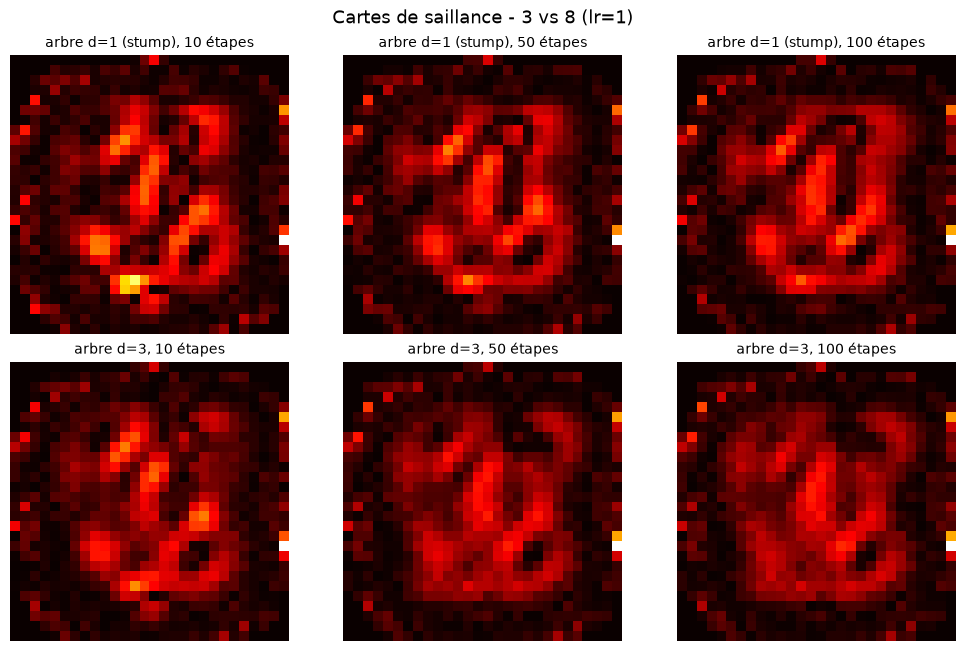

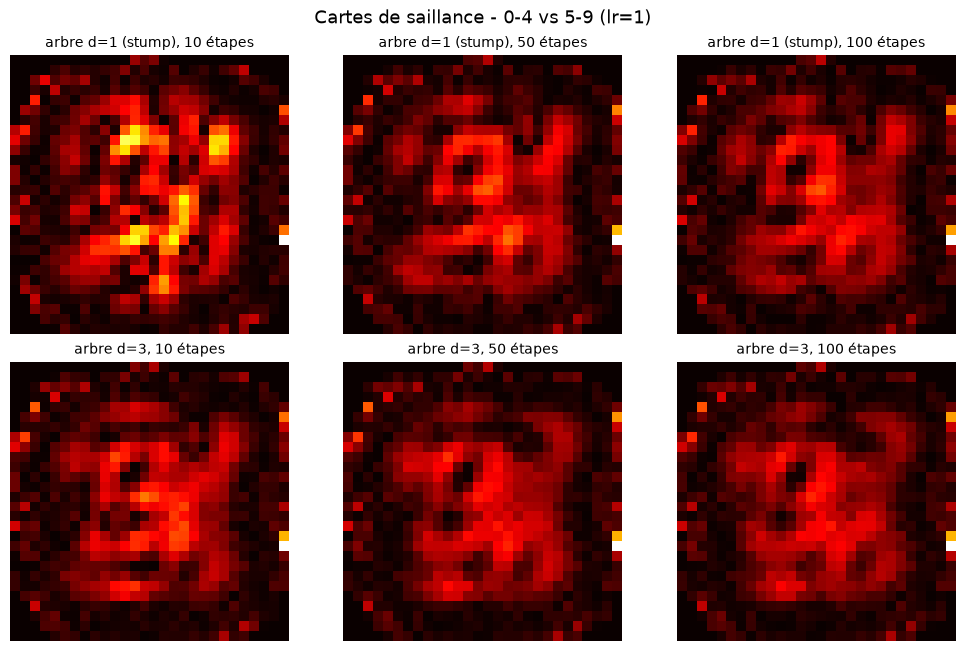

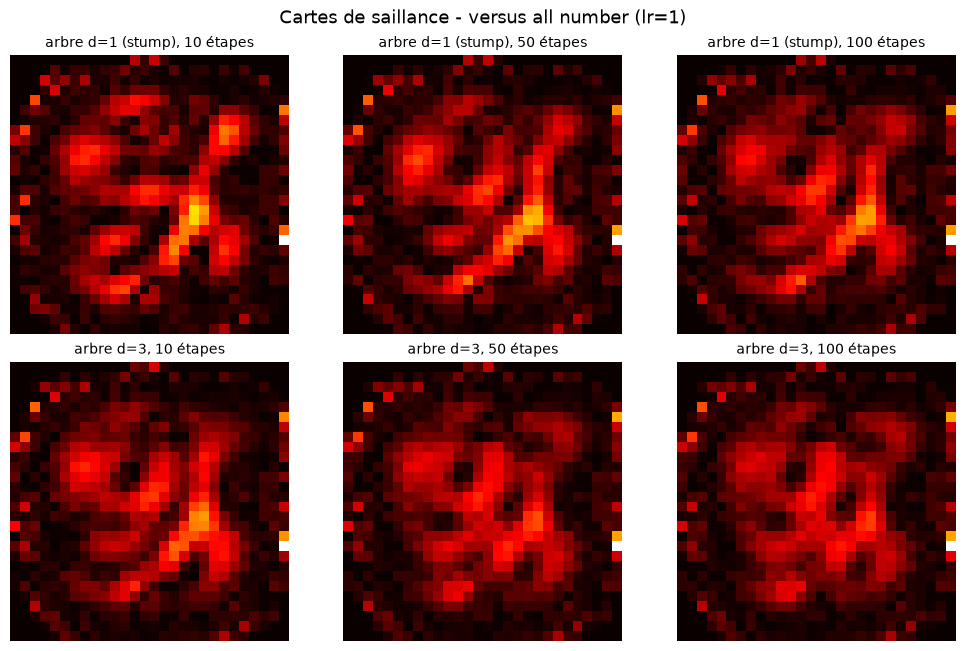

In [34]:
def saillance_embed(ab, Xb_pixels, n):
    imp = np.zeros(N_HIDDEN)
    for arbre, alpha in zip(ab.estimators_[:n], ab.estimator_weights_[:n]):
        imp += alpha * arbre.feature_importances_
    Z = embed(Xb_pixels)
    grad = ((Z > 0) * imp) @ W.T      # (n_images, 784) : rétropropagation vers les pixels
    return np.abs(grad).mean(axis=0).reshape(28, 28)

for tache in VERSUS:
    Xb_pix = VERSUS[tache][1]
    tracer_cartes(models_E, tache, ['arbre d=1 (stump)', 'arbre d=3'],
                  lambda ab, n, Xp=Xb_pix: saillance_embed(ab, Xp, n), prefixe="embedding_")

### ANNEXE

In [ ]:
# Quelles paires de chiffres sont le plus confondues ? (arbre prof. 5, 200 étapes)
yb10 = VERSUS["versus all number"][3]
preds_10 = preds[3]
cm = confusion_matrix(yb10, preds_10[("10 chiffres", "arbre prof. 5", 200)])
np.fill_diagonal(cm, 0)
top = sorted(((cm[i, j], i, j) for i in range(10) for j in range(10) if i != j), reverse=True)[:5]
for n, i, j in top:
    print(f"{n} images de {i} prédites comme {j}")

test embedding saillancy